# Project 02 · Decode old vs new recognition from human neuronal activity

**Question:** Can single-neuron firing in a human medial-temporal-lobe memory experiment distinguish objectively **old** (studied) versus **new** (unstudied) images? Do neural features outperform a stimulus-category-only model or a pre-stimulus activity control?

**Dataset:** [DANDI:000004](https://dandiarchive.org/dandiset/000004), **one published NWB session** from the Rutishauser laboratory (Chandravadia and colleagues). The selected public NWB file is about 73 MB and includes a `trials` table with `stim_phase`, `stim_on_time`, `category_name` and `new_old_labels_recog`. The field's description in the file says `new_old_labels_recog` is `0` for old and `1` for new, but the data show the reverse: it is `1` for exactly the recognition images that were shown during learning. This notebook reads `1` = old and checks that against the learning-phase images. The recording was obtained from a person with implanted clinical electrodes; it **does not represent the general population**.

*Corrected 25 October 2026: the first version used the documented coding, which swapped every Old/New label in the figures and outputs. Decoding scores do not depend on the label's direction and were unaffected.*

**Analysis:** trial-aligned spike counts during stimulus viewing → neural population raster/PSTH → temporal holdout classification → comparison with category-only and pre-stimulus neural controls → a refitted null that keeps image category.

**Important:** This is a **single-session exploratory analysis**. Even strong decoding cannot establish a general neural signature of episodic recognition, neuronal causality, or cross-participant reproducibility. The target is objective stimulus novelty, **not** the participant's subjective recollection, decision or confidence.

In [1]:
%pip -q install "pynwb>=3,<5" "hdmf>=4,<6" "requests>=2.31" "scikit-learn>=1.4,<2" "pandas>=2,<3" "matplotlib>=3.8,<4" "scipy>=1.11,<2"

In [2]:
from pathlib import Path
import json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from pynwb import NWBHDF5IO
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (balanced_accuracy_score,roc_auc_score,accuracy_score,
    ConfusionMatrixDisplay, classification_report)

SEED=42
# Stable asset download URL used in the official PyNWB tutorial.
ASSET_URL='https://api.dandiarchive.org/api/assets/0f57f0b0-f021-42bb-8eaa-56cd482e2a29/download/'
DATA=Path('/content/neurotech_data') if Path('/content').exists() else Path('neurotech_data')
OUT=Path('/content/neurotech_results/02_human_recognition') if Path('/content').exists() else Path('neurotech_results/02_human_recognition')
DATA.mkdir(parents=True,exist_ok=True);OUT.mkdir(parents=True,exist_ok=True)
FILE=DATA/'sub-P11HMH_ses-20061101_ecephys+image.nwb'
print('Output:',OUT)

Output: /content/neurotech_results/02_human_recognition


In [3]:
# Fetch ~73MB NWB example file, with HTTP checks and resumable local caching.
# This is only run in Colab where internet access is available.
if not FILE.exists() or FILE.stat().st_size<1_000_000:
    with requests.get(ASSET_URL,stream=True,timeout=(20,120)) as response:
        response.raise_for_status()
        with FILE.open('wb') as f:
            for chunk in response.iter_content(chunk_size=2**20):
                if chunk: f.write(chunk)
print('NWB local size (MiB):',round(FILE.stat().st_size/2**20,2))

NWB local size (MiB): 69.26


In [4]:
# Read only spike times and trial metadata; do NOT load image arrays or raw continuous signals.
with NWBHDF5IO(str(FILE),mode='r',load_namespaces=True) as io:
    nwb=io.read()
    if nwb.units is None or nwb.trials is None:
        raise ValueError('Expected NWB units and trials tables.')
    trial_table=nwb.trials.to_dataframe().copy()
    units_table=nwb.units.to_dataframe()
    spikes=[np.sort(np.asarray(st,dtype=float)) for st in units_table['spike_times'].tolist()]
    unit_ids=units_table.index.to_numpy().tolist()
    print('Session:',nwb.identifier,'| units:',len(spikes),'| trials:',len(trial_table))
    print('Trial columns:',trial_table.columns.tolist())
    print('Stimulus phases:',trial_table['stim_phase'].value_counts(dropna=False).to_dict())

if not spikes: raise RuntimeError('No spike-sorted units found for this NWB session.')
# Recognition trials only. Learning-trial labels are missing or "NA" by design.
recognition=trial_table[trial_table['stim_phase'].astype(str).str.lower().str.contains('recog')].copy()
# The field's description says 0 = old, but the data show 1 = old (checked against the learning-phase images below).
recognition['new_label']=1-pd.to_numeric(recognition['new_old_labels_recog'],errors='coerce')
recognition['stim_on_time']=pd.to_numeric(recognition['stim_on_time'],errors='coerce')
recognition=recognition[recognition.new_label.isin([0,1]) & recognition.stim_on_time.notna()]
recognition=recognition.sort_values('stim_on_time').reset_index(drop=True)
recognition['new_label']=recognition.new_label.astype(int)
recognition['category_name']=recognition.category_name.fillna('unknown').astype(str)
learned=set(trial_table.loc[trial_table['stim_phase'].astype(str).str.lower().str.contains('learn'),'external_image_file'].dropna())
assert ((recognition.new_label==0)==recognition['external_image_file'].isin(learned)).all(), \
    'Label disagrees with the learning-phase images: check this file before analysing it.'
print('Label check: "old" matches the images shown during learning on all',len(recognition),'trials')
assert recognition.new_label.nunique()==2,'Need both old and new stimuli.'
assert len(recognition)>=30,'Too few valid recognition trials for this example.'
print('Recognition trials:',len(recognition),'| labels:',recognition.new_label.value_counts().to_dict())
display(recognition[['stim_on_time','new_label','category_name']].head(8))
recognition[['stim_on_time','new_label','category_name']].to_csv(OUT/'recognition_trial_index.csv',index=False)

Session: H11_9 | units: 25 | trials: 200
Trial columns: ['start_time', 'stop_time', 'stim_on_time', 'stim_off_time', 'delay1_time', 'delay2_time', 'stim_phase', 'stimCategory', 'category_name', 'external_image_file', 'new_old_labels_recog', 'response_value', 'response_time']
Stimulus phases: {'learn': 100, 'recog': 100}
Label check: "old" matches the images shown during learning on all 100 trials
Recognition trials: 100 | labels: {1: 50, 0: 50}


,stim_on_time,new_label,category_name
0,8737.451703,1,mobility
1,8743.522823,0,houses
2,8748.519303,1,landscapes
3,8752.002383,0,phones
4,8755.294703,0,phones
5,8758.297463,0,phones
6,8762.071223,1,smallAnimal
7,8765.571423,0,landscapes


## Pre-response neural features and negative controls

Spike counts from **0.05 to 0.85 seconds after image onset** approximate early stimulus-evoked firing. A **−0.85 to −0.05 second** pre-stimulus window is a negative control: if that window also strongly predicts old/new labels, temporal drift or trial-order confounding is plausible. Restricting analysis to early stimulus processing avoids deliberately using response-period activity, but cannot isolate familiarity from perceptual differences.

The classifier learns from **one trial per row**, **one recorded neuron per column**. Its predictive target is the *ground-truth studied/unstudied condition*. When there are few neurons or trials, results can be noisy.

In [5]:
# Efficient event-window spike counting. No labels enter this function.
def spike_count_matrix(spike_arrays, onsets, start, stop):
    onsets=np.asarray(onsets,dtype=float)
    if not start<stop: raise ValueError('Start must precede stop')
    X=np.zeros((len(onsets),len(spike_arrays)),dtype=float)
    for j, st in enumerate(spike_arrays):
        st=np.sort(np.asarray(st,dtype=float))
        X[:,j]=np.searchsorted(st,onsets+stop,side='left') - \
               np.searchsorted(st,onsets+start,side='left')
    return X

onsets=recognition.stim_on_time.to_numpy()
y=recognition.new_label.to_numpy()  # 0=old, 1=new
X_post=spike_count_matrix(spikes,onsets,.05,.85)
X_pre=spike_count_matrix(spikes,onsets,-.85,-.05)
print('Feature shape:',X_post.shape,'| fraction nonzero:',np.mean(X_post>0).round(3))
assert X_post.shape==X_pre.shape==(len(y),len(spikes))
assert np.all(X_post>=0) and np.all(X_pre>=0)
assert np.issubdtype(X_post.dtype,np.number)

Feature shape: (100, 25) | fraction nonzero: 0.491


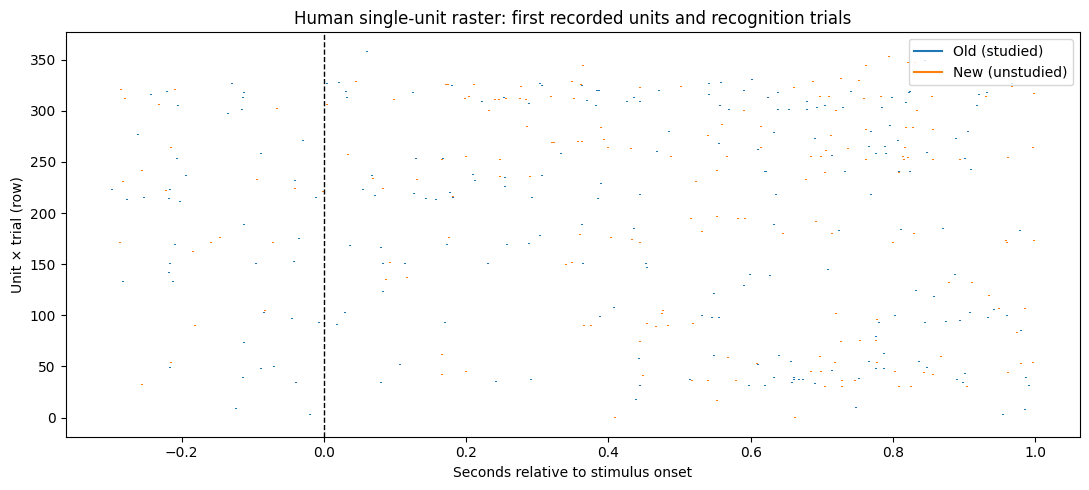

In [6]:
# Visualization 1: raster of the first several units around recognition image onset.
N_UNITS=min(12,len(spikes))
N_SHOW=min(30,len(onsets))
fig,ax=plt.subplots(figsize=(11,5))
for j in range(N_UNITS):
    for k in range(N_SHOW):
        t0=onsets[k]; st=spikes[j]
        rel=st[(st>=t0-.3)&(st<t0+1.0)]-t0
        # One vertical row per unit-trial combination; colored by ground-truth stimulus status.
        ax.eventplot(rel,lineoffsets=j*N_SHOW+k,linelengths=.8,
                     colors=('tab:blue' if y[k]==0 else 'tab:orange'))
ax.axvline(0,color='black',ls='--',lw=1)
ax.set(xlabel='Seconds relative to stimulus onset',ylabel='Unit × trial (row)',
       title='Human single-unit raster: first recorded units and recognition trials')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],color='tab:blue',label='Old (studied)'),
                   Line2D([0],[0],color='tab:orange',label='New (unstudied)')],loc='upper right')
fig.tight_layout();fig.savefig(OUT/'recognition_raster.png',dpi=170);plt.show()

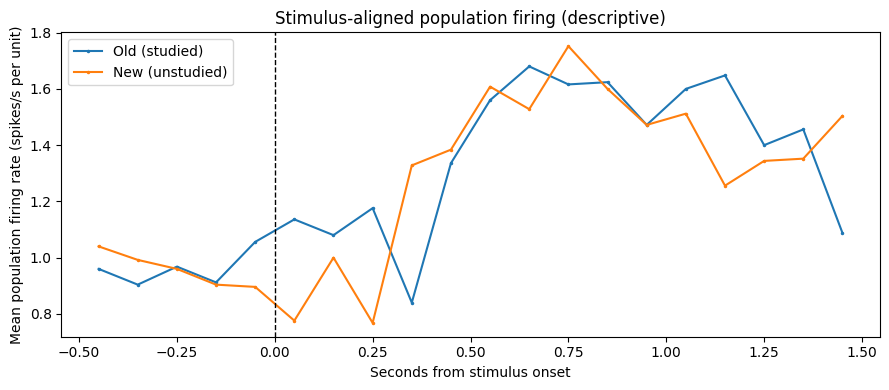

In [7]:
# Visualization 2: mean population firing around stimulus onset, by condition.
# This is descriptive only; no errorbars implying independent neurons are shown.
bins=np.arange(-.5,1.501,.1)
centers=(bins[:-1]+bins[1:])/2
rates=[]
for label in [0,1]:
    idx=np.flatnonzero(y==label)
    total=np.zeros(len(centers),dtype=float)
    for t0 in onsets[idx]:
        for st in spikes:
            total += np.histogram(st[(st>=t0+bins[0]) & (st<t0+bins[-1])]-t0,bins)[0]
    rates.append(total/max(len(idx)*len(spikes)*(bins[1]-bins[0]),1))
fig,ax=plt.subplots(figsize=(9,4))
for label,rate in zip(['Old (studied)','New (unstudied)'],rates):
    ax.plot(centers,rate,label=label,marker='.',ms=3)
ax.axvline(0,color='black',lw=1,ls='--')
ax.set(xlabel='Seconds from stimulus onset',ylabel='Mean population firing rate (spikes/s per unit)',
       title='Stimulus-aligned population firing (descriptive)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'population_psth.png',dpi=170);plt.show()

## Chronological holdout evaluation

The last 25% of recognition trials form an **untouched future block**. This tests prediction later within the same session—not prediction for a new participant. It is stricter about temporal drift than randomly splitting adjacent trials, although still susceptible to category, recording-state and sequence differences. Check class prevalence in both blocks.

We evaluate three frozen comparison models on the *same test trials*:

1. **Post-stimulus neural firing** (primary exploratory decoder)
2. **Pre-stimulus firing** (negative-control decoder)
3. **Stimulus category only** (non-neural benchmark). In this task old and new images are balanced within each category, so category carries no information about true status. Under a chronological split, a category imbalance in the training block forces the opposite imbalance in the test block, so this model is expected to score *below* chance. A neural decoder that relies on category-selective neurons inherits part of that bias, which is why the final test compares it with a within-category null rather than with 0.5

No hyperparameters are selected using the test block. A difference in accuracy is descriptive until validated across additional independent sessions.

In [8]:
N=len(y)
cut=int(np.floor(N*.75))
itr=np.arange(cut); ite=np.arange(cut,N)
if len(np.unique(y[itr]))!=2 or len(np.unique(y[ite]))!=2:
    raise RuntimeError('The chronological split has one target class. Examine class order and predefine an alternative evaluation design.')
print('Training n=',len(itr),'test n=',len(ite))
print('Train new proportion:',np.mean(y[itr]).round(3),'Test new proportion:',np.mean(y[ite]).round(3))
status=np.where(y==0,'old','new')
print('Old/new per category, whole session, training block and test block:')
display(pd.concat({'session':pd.crosstab(recognition.category_name,status),
                   'train':pd.crosstab(recognition.category_name.iloc[itr],status[itr]),
                   'test':pd.crosstab(recognition.category_name.iloc[ite],status[ite])},axis=1).fillna(0).astype(int))

neural_model=lambda: Pipeline([('scale',StandardScaler()),
     ('logit',LogisticRegression(max_iter=3000,random_state=SEED,class_weight='balanced'))])
# Category-only baseline encoding is trained on the training block only.
category_model=Pipeline([
    ('category',OneHotEncoder(handle_unknown='ignore')),
    ('logit',LogisticRegression(max_iter=3000,random_state=SEED,class_weight='balanced'))])
models_and_data={
    'post_stimulus_neural':(neural_model(),X_post),
    'pre_stimulus_control':(neural_model(),X_pre),
    'category_only':(category_model,recognition[['category_name']])
}
metric_rows=[]
results=recognition[['stim_on_time','new_label','category_name']].iloc[ite].reset_index(drop=True).copy()
for name,(model,feat) in models_and_data.items():
    x_train=feat.iloc[itr] if hasattr(feat,'iloc') else feat[itr]
    x_test=feat.iloc[ite] if hasattr(feat,'iloc') else feat[ite]
    model.fit(x_train,y[itr])
    pred=model.predict(x_test)
    prob=model.predict_proba(x_test)[:,1]
    metrics={'model':name,'n_train':len(itr),'n_test':len(ite),
             'balanced_accuracy':balanced_accuracy_score(y[ite],pred),
             'accuracy':accuracy_score(y[ite],pred),
             'roc_auc':roc_auc_score(y[ite],prob)}
    metric_rows.append(metrics)
    results[name+'_prediction']=pred
    results[name+'_p_new']=prob
    print('\n',name,metrics)
    print(classification_report(y[ite],pred,target_names=['Old','New'],zero_division=0))

scores=pd.DataFrame(metric_rows)
display(scores)
scores.to_csv(OUT/'decoder_metrics.csv',index=False)
results.to_csv(OUT/'heldout_trial_predictions.csv',index=False)

Training n= 75 test n= 25
Train new proportion: 0.467 Test new proportion: 0.6
Old/new per category, whole session, training block and test block:


session     train     test    
col_0             new old   new old  new old
category_name                               
houses             10  10     8   8    2   2
landscapes         10  10     6   9    4   1
mobility           10  10     8   6    2   4
phones             10  10     7   9    3   1
smallAnimal        10  10     6   8    4   2


 post_stimulus_neural {'model': 'post_stimulus_neural', 'n_train': 75, 'n_test': 25, 'balanced_accuracy': np.float64(0.6333333333333333), 'accuracy': 0.6, 'roc_auc': np.float64(0.66)}
              precision    recall  f1-score   support

         Old       0.50      0.80      0.62        10
         New       0.78      0.47      0.58        15

    accuracy                           0.60        25
   macro avg       0.64      0.63      0.60        25
weighted avg       0.67      0.60      0.60        25


 pre_stimulus_control {'model': 'pre_stimulus_control', 'n_train': 75, 'n_test': 25, 'balanced_accuracy': np.float64(0.4833333333333333), 'accuracy': 0.44, 'roc_auc': np.float64(0.4266666666666667)}
              precision    recall  f1-score   support

         Old       0.39      0.70      0.50        10
         New       0.57      0.27      0.36        15

    accuracy                           0.44        25
   macro avg       0.48      0.48      0.43        25
weighted avg    

,model,n_train,n_test,balanced_accuracy,accuracy,roc_auc
0,post_stimulus_neural,75,25,0.633333,0.60,0.660000
1,pre_stimulus_control,75,25,0.483333,0.44,0.426667
2,category_only,75,25,0.333333,0.32,0.310000


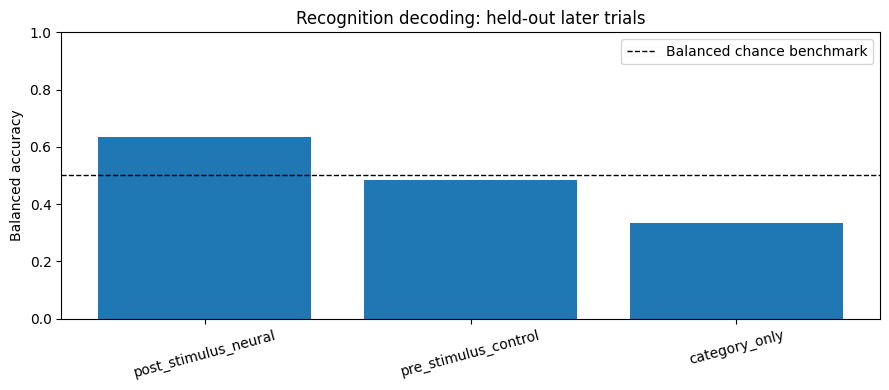

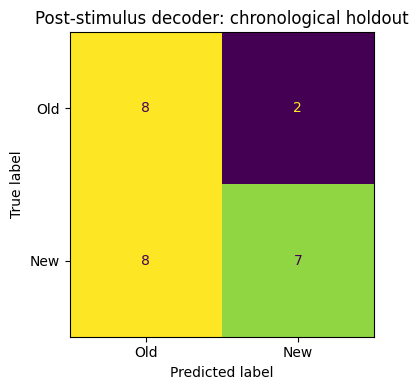

In [9]:
# Visualization 3: three prediction benchmarks on the same unseen chronological block.
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(scores.model,scores.balanced_accuracy)
ax.axhline(.5,color='black',linestyle='--',lw=1,label='Balanced chance benchmark')
ax.set(ylabel='Balanced accuracy',ylim=(0,1),title='Recognition decoding: held-out later trials')
ax.tick_params(axis='x',rotation=15)
ax.legend();fig.tight_layout();fig.savefig(OUT/'decoding_comparison.png',dpi=170);plt.show()

fig,ax=plt.subplots(figsize=(4.4,4))
ConfusionMatrixDisplay.from_predictions(y[ite],results['post_stimulus_neural_prediction'],
   display_labels=['Old','New'],ax=ax,colorbar=False)
ax.set_title('Post-stimulus decoder: chronological holdout')
fig.tight_layout();fig.savefig(OUT/'recognition_confusion.png',dpi=170);plt.show()

In [10]:
# Is the post-stimulus decoder better than one that only has access to image category?
# Null: shuffle neural activity among trials of the same image category (both blocks), refit on the training block and
# score the same held-out block. This keeps category-selective firing and the stimulus set's category balance, and
# breaks any trial-level link with true status. Exploratory: one session and 25 test trials.
rng=np.random.default_rng(SEED)
cat=recognition.category_name.to_numpy()
def shuffled_within_category():
    idx=np.arange(len(cat))
    for c in np.unique(cat):
        members=np.flatnonzero(cat==c); idx[members]=rng.permutation(members)
    return idx
observed={k:scores.loc[scores.model=='post_stimulus_neural',k].iat[0] for k in ('balanced_accuracy','roc_auc')}
null=[]
for _ in range(1000):
    Xs=X_post[shuffled_within_category()]
    m=neural_model().fit(Xs[itr],y[itr])
    null.append((balanced_accuracy_score(y[ite],m.predict(Xs[ite])),roc_auc_score(y[ite],m.predict_proba(Xs[ite])[:,1])))
null=np.array(null)
null_summary={}
for j,k in enumerate(('balanced_accuracy','roc_auc')):
    p=(1+np.count_nonzero(null[:,j]>=observed[k]))/(1+len(null))
    null_summary[k]={'observed':round(float(observed[k]),3),'null_mean':round(float(null[:,j].mean()),3),'p_one_sided':round(p,4)}
    print(f'{k}: observed {observed[k]:.3f}, within-category null mean {null[:,j].mean():.3f}, one-sided p = {p:.3f}')
print('Exploratory: one session and 25 test trials. Notebook 03 repeats this across all sessions.')

balanced_accuracy: observed 0.633, within-category null mean 0.495, one-sided p = 0.117
roc_auc: observed 0.660, within-category null mean 0.497, one-sided p = 0.098
Exploratory: one session and 25 test trials. Notebook 03 repeats this across all sessions.


In [11]:
settings={'dataset':'DANDI 000004', 'dataset_url':'https://dandiarchive.org/dandiset/000004',
          'asset_download_url':ASSET_URL,'nwb_filename':FILE.name,
          'n_units':len(spikes),'n_recognition_trials':int(len(y)),
          'stored_label_map':{'1':'old (shown during learning)','0':'new'},'y_coding':{'0':'old','1':'new'},
          'null_test':'within-category shuffle of neural activity, refit, 1000 repeats','null_result':null_summary,
          'features':{'post_seconds':[.05,.85],'pre_control_seconds':[-.85,-.05]},
          'evaluation':'first 75% trials train; last 25% trials test',
          'seed':SEED,'python':platform.python_version(),
          'sklearn':__import__('sklearn').__version__,'pynwb':__import__('pynwb').__version__}
(OUT/'settings.json').write_text(json.dumps(settings,indent=2))
print('Saved:',*[p.name for p in sorted(OUT.iterdir())],sep='\n - ')
# Optional Google Drive export:
# from google.colab import drive
# drive.mount('/content/drive')
# import shutil
# shutil.copytree(OUT,'/content/drive/MyDrive/cognitive_neurotech/02_human_recognition',dirs_exist_ok=True)

Saved:
 - decoder_metrics.csv
 - decoding_comparison.png
 - heldout_trial_predictions.csv
 - population_psth.png
 - recognition_confusion.png
 - recognition_raster.png
 - recognition_trial_index.csv
 - settings.json


## Scientific interpretation and next studies

- **Stimulus novelty ≠ subjective memory.** The label is whether the image was presented previously. The participant may remember incorrectly or express uncertainty. The response and confidence information provide a *later* separate research question.
- **A decoder is not an explanation.** Above-chance prediction does not prove that the recorded neurons encode episodic familiarity specifically, particularly without matching visual image features or controlling stimulus category and study conditions.
- **A pre-stimulus control matters.** If pre-stimulus predictions approach post-stimulus scores, investigate temporal drift, trial sequences, and baseline differences before attributing results to memory.
- **The category-only model is not a bar to clear.** Old and new are balanced within each category, so it should score at or below chance under a chronological split. Compare the neural decoder with the within-category null instead, which still cannot rule out richer visual confounds.
- **One session is not population evidence.** No new-person test is possible with this session alone; expand to multiple sessions, check for repeated participants, and fit session-specific models where unit identities change.

**Good next questions:** Can the model decode *reported old/new decisions* rather than correct status? Does certainty of recognition modulate activity? Does predictive information change over the post-onset interval? What happens when stimuli are matched by semantic category?

**Ethical language for GitHub:** These are analyses of existing published public scientific data, not studies that you collected. No clinical claims are supported. Cite and credit the original dataset and research team.

### Results archive

The archive holds only generated figures, CSV files and settings, not the raw experimental data. Download it from the Files panel on the left.

In [12]:
import shutil
results_zip = shutil.make_archive(str(OUT), 'zip', root_dir=str(OUT))
print('Result archive (download from the Files panel):', results_zip)

Result archive (download from the Files panel): /content/neurotech_results/02_human_recognition.zip
